# Importing The Libraries 

In [1]:
import pandas as pd

## Loading the dataset

In [2]:
df = pd.read_csv("data/market_data.csv")

print("Data loaded successfully!")
print("Shape:", df.shape)

df.head()

Data loaded successfully!
Shape: (100, 6)


,Date,Open,High,Low,Close,Volume
0,2026-04-23,275.045,275.77,271.65,273.43,33399639.0
1,2026-04-24,272.755,273.06,269.65,271.06,38157110.0
2,2026-04-27,266.090,268.36,265.07,267.61,41466762.0
3,2026-04-28,272.335,273.23,268.66,270.71,40018940.0
4,2026-04-29,267.550,271.04,267.04,270.17,30047869.0


### checking the missing values

In [3]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


### checking the duplicate rows

In [4]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


### Describing the dataset

In [5]:
df.describe()

,Open,High,Low,Close,Volume
count,100.000000,100.000000,100.000000,100.000000,1.000000e+02
mean,305.801910,309.739634,302.834768,306.574800,5.214714e+07
std,16.705989,16.842256,16.629664,17.004507,2.689002e+07
min,266.090000,268.360000,265.070000,267.610000,2.586981e+07
25%,295.327500,300.472500,293.360000,295.870000,3.980752e+07
50%,308.040000,311.755000,305.705000,308.865000,4.594402e+07
75%,315.781250,319.529925,311.975000,316.220000,5.349850e+07
max,340.030000,344.569900,337.350100,340.080000,2.617754e+08


In [6]:
print("Start Date:", df.index.min())
print("End Date:", df.index.max())

Start Date: 0
End Date: 99


In [7]:
df= pd.read_csv(
    "data/market_data.csv",
    index_col="Date",
    parse_dates=True
)

print("Start Date:", df.index.min())
print("End Date:", df.index.max())

Start Date: 2026-04-23 00:00:00
End Date: 2026-09-15 00:00:00


## Data Visualizations

In [8]:
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv(
    "data/market_data.csv",
    index_col="Date",
    parse_dates=True
)

df.head()

,Open,High,Low,Close,Volume
Date,,,,,
2026-04-23,275.045,275.77,271.65,273.43,33399639.0
2026-04-24,272.755,273.06,269.65,271.06,38157110.0
2026-04-27,266.090,268.36,265.07,267.61,41466762.0
2026-04-28,272.335,273.23,268.66,270.71,40018940.0
2026-04-29,267.550,271.04,267.04,270.17,30047869.0


# visualizing the close price trend
- To understand how close price is moved with stock price

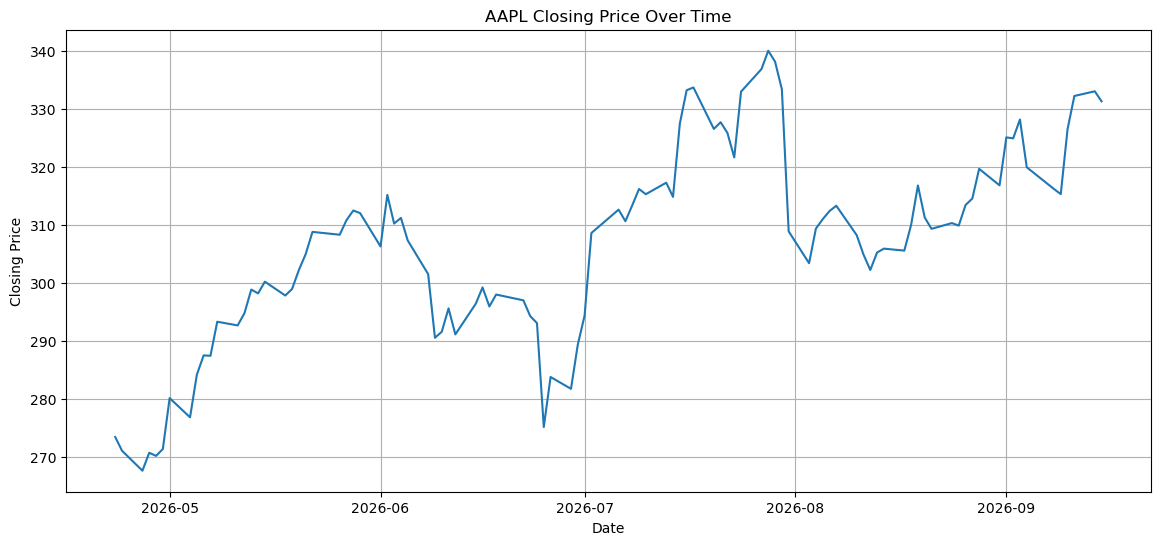

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"])

plt.title("AAPL Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.grid(True)
plt.show()

## vislualizing the open,high,low,close price trend
- To understand the daily trading range and price movement

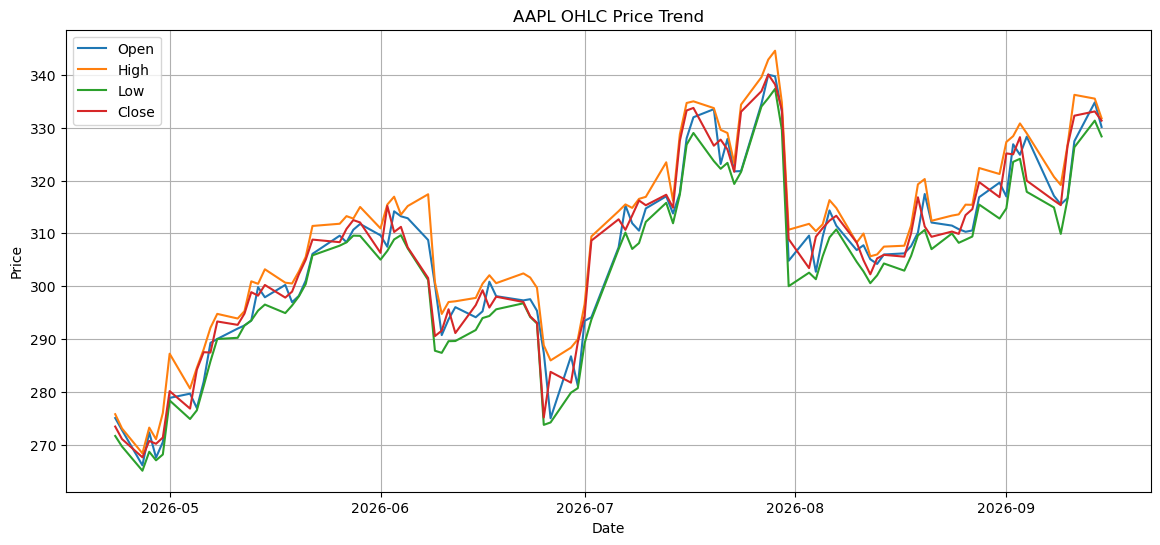

In [11]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Open"], label="Open")
plt.plot(df.index, df["High"], label="High")
plt.plot(df.index, df["Low"], label="Low")
plt.plot(df.index, df["Close"], label="Close")

plt.title("AAPL OHLC Price Trend")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)
plt.show()

## calculating daily return 
- To understand how stock price % changes daily

In [12]:
df["Daily_Return"] = df["Close"].pct_change()
df[["Close", "Daily_Return"]].head(10)

,Close,Daily_Return
Date,,
2026-04-23,273.43,NaN
2026-04-24,271.06,-0.008668
2026-04-27,267.61,-0.012728
2026-04-28,270.71,0.011584
2026-04-29,270.17,-0.001995
2026-04-30,271.35,0.004368
2026-05-01,280.14,0.032394
2026-05-04,276.83,-0.011816
2026-05-05,284.18,0.026551


In [13]:
df["Daily_Return"].describe()

count    99.000000
mean      0.002105
std       0.018074
min      -0.073539
25%      -0.007841
50%       0.003126
75%       0.011633
max       0.048407
Name: Daily_Return, dtype: float64

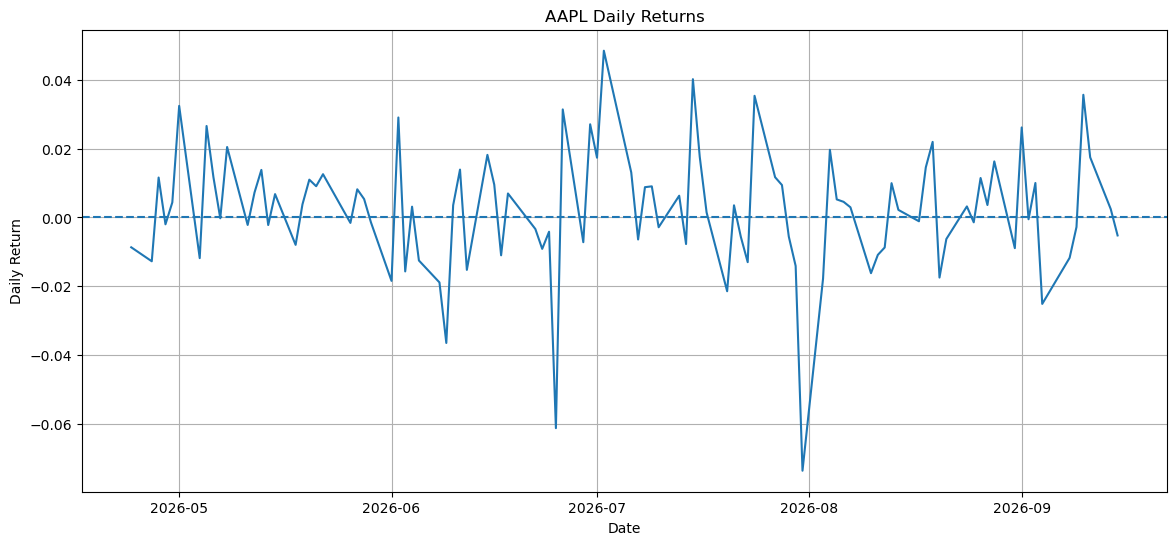

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Daily_Return"])

plt.title("AAPL Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")

plt.axhline(0, linestyle="--")

plt.grid(True)
plt.show()

## calculating 20-day rolling volatility
- To measure how returns fluctuate in recent 20 trading days 

In [15]:
df["Volatility_20D"] = (
    df["Daily_Return"]
    .rolling(window=20)
    .std()
)

df[["Daily_Return", "Volatility_20D"]].tail(10)

,Daily_Return,Volatility_20D
Date,,
2026-09-01,0.026132,0.011937
2026-09-02,-0.000523,0.011938
2026-09-03,0.010001,0.012055
2026-09-04,-0.025106,0.013545
2026-09-08,-0.011720,0.013279
2026-09-09,-0.002783,0.013007
2026-09-10,0.035612,0.014783
2026-09-11,0.017454,0.015035
2026-09-14,0.002438,0.015034


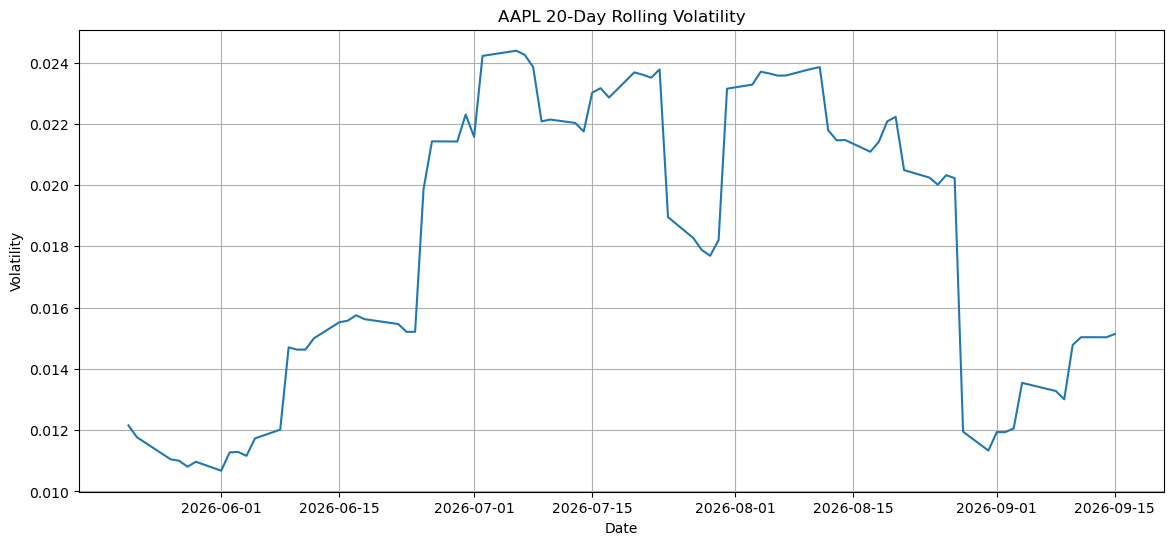

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Volatility_20D"])

plt.title("AAPL 20-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.grid(True)
plt.show()

## Technical indicators
### calculating 20-day simple moving average
- To observe short-term price trend in smoothly

In [17]:
df["SMA_20"] = df["Close"].rolling(window=20).mean()


df[["Close", "SMA_20"]].tail(10)

,Close,SMA_20
Date,,
2026-09-01,325.13,311.3200
2026-09-02,324.96,312.0180
2026-09-03,328.21,312.8080
2026-09-04,319.97,313.1400
2026-09-08,316.22,313.5380
2026-09-09,315.34,314.0595
2026-09-10,326.57,315.2755
2026-09-11,332.27,316.6260
2026-09-14,333.08,317.9835


## comparing closing price and SMA
- To compare with price trend SMA

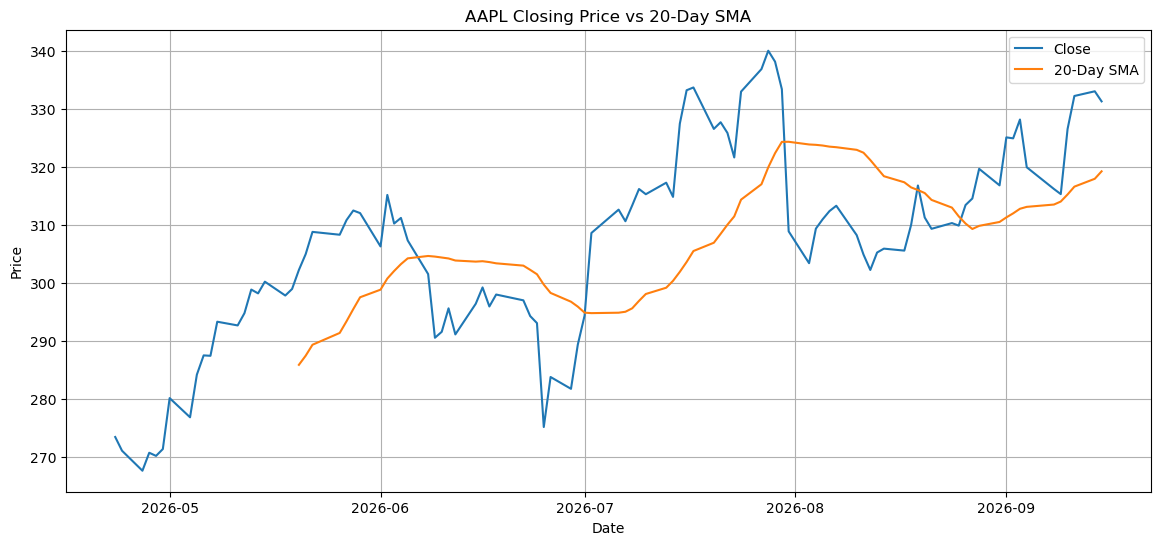

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"], label="Close")
plt.plot(df.index, df["SMA_20"], label="20-Day SMA")

plt.title("AAPL Closing Price vs 20-Day SMA")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)
plt.show()

## calculating 20-day Exponential Moving Average
- To give more importance to recent price

In [19]:
df["EMA_20"] = df["Close"].ewm(
    span=20,
    adjust=False
).mean()

df[["Close", "SMA_20", "EMA_20"]].tail(10)

,Close,SMA_20,EMA_20
Date,,,
2026-09-01,325.13,311.3200,314.355310
2026-09-02,324.96,312.0180,315.365280
2026-09-03,328.21,312.8080,316.588587
2026-09-04,319.97,313.1400,316.910626
2026-09-08,316.22,313.5380,316.844852
2026-09-09,315.34,314.0595,316.701533
2026-09-10,326.57,315.2755,317.641387
2026-09-11,332.27,316.6260,319.034588
2026-09-14,333.08,317.9835,320.372247


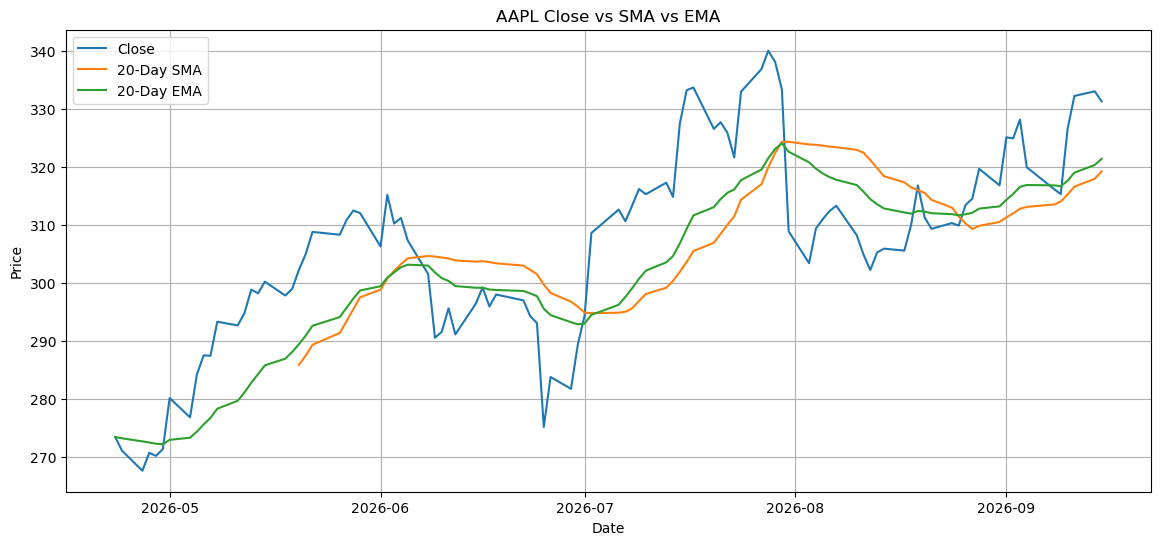

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["Close"], label="Close")
plt.plot(df.index, df["SMA_20"], label="20-Day SMA")
plt.plot(df.index, df["EMA_20"], label="20-Day EMA")

plt.title("AAPL Close vs SMA vs EMA")
plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
delta = df["Close"].diff()

gain = delta.clip(lower=0)

loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

# RSI formula
df["RSI_14"] = 100 - (100 / (1 + rs))

df[["Close", "RSI_14"]].tail(10)

,Close,RSI_14
Date,,
2026-09-01,325.13,75.365854
2026-09-02,324.96,73.308093
2026-09-03,328.21,74.843889
2026-09-04,319.97,63.632916
2026-09-08,316.22,55.946206
2026-09-09,315.34,48.384999
2026-09-10,326.57,64.730851
2026-09-11,332.27,70.618928
2026-09-14,333.08,70.523466


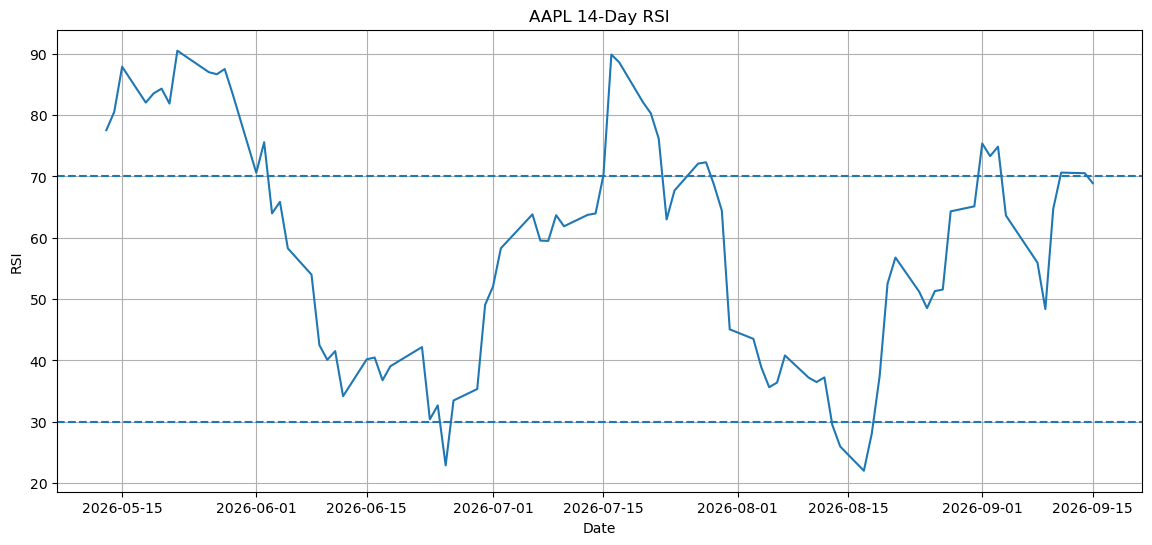

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["RSI_14"])

plt.axhline(70, linestyle="--")
plt.axhline(30, linestyle="--")

plt.title("AAPL 14-Day RSI")
plt.xlabel("Date")
plt.ylabel("RSI")

plt.grid(True)
plt.show()

In [23]:
ema_12 = df["Close"].ewm(
    span=12,
    adjust=False
).mean()

ema_26 = df["Close"].ewm(
    span=26,
    adjust=False
).mean()

# MACD line
df["MACD"] = ema_12 - ema_26

# Signal line = 9-day EMA of MACD
df["MACD_Signal"] = df["MACD"].ewm(
    span=9,
    adjust=False
).mean()

df[["Close", "MACD", "MACD_Signal"]].tail(10)

,Close,MACD,MACD_Signal
Date,,,
2026-09-01,325.13,1.198116,-0.318388
2026-09-02,324.96,1.886065,0.122503
2026-09-03,328.21,2.662822,0.630567
2026-09-04,319.97,2.583725,1.021198
2026-09-08,316.22,2.193165,1.255592
2026-09-09,315.34,1.791978,1.362869
2026-09-10,326.57,2.353076,1.560910
2026-09-11,332.27,3.220569,1.892842
2026-09-14,333.08,3.928142,2.299902


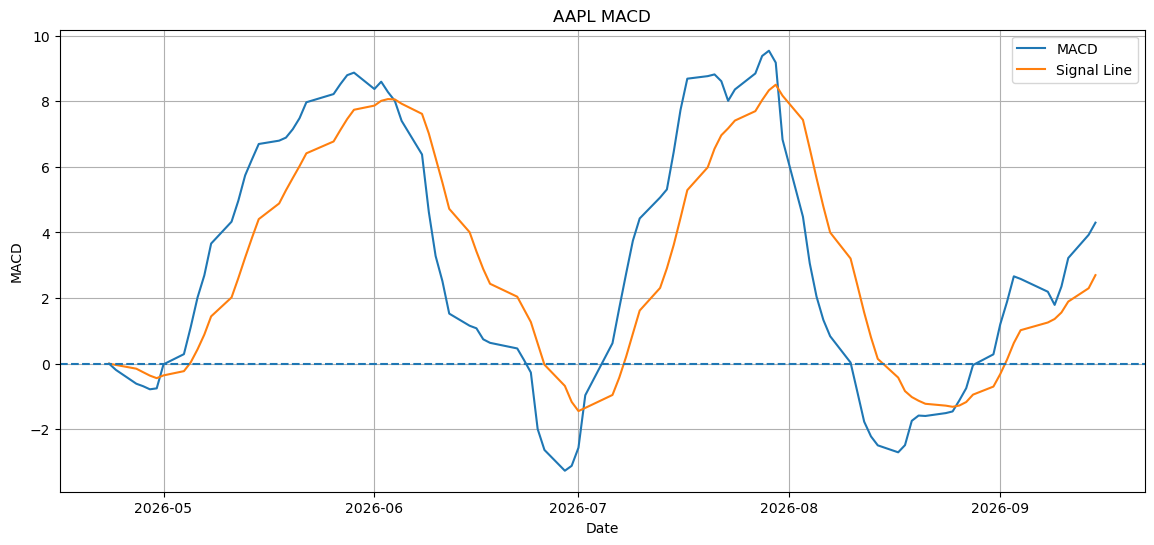

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["MACD"], label="MACD")
plt.plot(df.index, df["MACD_Signal"], label="Signal Line")

plt.axhline(0, linestyle="--")

plt.title("AAPL MACD")
plt.xlabel("Date")
plt.ylabel("MACD")

plt.legend()
plt.grid(True)
plt.show()

In [25]:
df[[
    "Close",
    "Daily_Return",
    "Volatility_20D",
    "SMA_20",
    "EMA_20",
    "RSI_14",
    "MACD",
    "MACD_Signal"
]].tail(10)

,Close,Daily_Return,Volatility_20D,SMA_20,EMA_20,RSI_14,MACD,MACD_Signal
Date,,,,,,,,
2026-09-01,325.13,0.026132,0.011937,311.3200,314.355310,75.365854,1.198116,-0.318388
2026-09-02,324.96,-0.000523,0.011938,312.0180,315.365280,73.308093,1.886065,0.122503
2026-09-03,328.21,0.010001,0.012055,312.8080,316.588587,74.843889,2.662822,0.630567
2026-09-04,319.97,-0.025106,0.013545,313.1400,316.910626,63.632916,2.583725,1.021198
2026-09-08,316.22,-0.011720,0.013279,313.5380,316.844852,55.946206,2.193165,1.255592
2026-09-09,315.34,-0.002783,0.013007,314.0595,316.701533,48.384999,1.791978,1.362869
2026-09-10,326.57,0.035612,0.014783,315.2755,317.641387,64.730851,2.353076,1.560910
2026-09-11,332.27,0.017454,0.015035,316.6260,319.034588,70.618928,3.220569,1.892842
2026-09-14,333.08,0.002438,0.015034,317.9835,320.372247,70.523466,3.928142,2.299902


In [26]:
df.columns

Index(['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return',
       'Volatility_20D', 'SMA_20', 'EMA_20', 'RSI_14', 'MACD', 'MACD_Signal'],
      dtype='object')

In [27]:
df["Target_Close"] = df["Close"].shift(-1)

df[["Close", "Target_Close"]].head(10)

,Close,Target_Close
Date,,
2026-04-23,273.43,271.06
2026-04-24,271.06,267.61
2026-04-27,267.61,270.71
2026-04-28,270.71,270.17
2026-04-29,270.17,271.35
2026-04-30,271.35,280.14
2026-05-01,280.14,276.83
2026-05-04,276.83,284.18
2026-05-05,284.18,287.51


In [28]:
df["Close_Lag_1"] = df["Close"].shift(1)

In [29]:
df["Close_Lag_2"] = df["Close"].shift(2)

In [30]:
df["Close_Lag_5"] = df["Close"].shift(5)

In [31]:
df[
    [
        "Close",
        "Close_Lag_1",
        "Close_Lag_2",
        "Close_Lag_5",
        "Target_Close"
    ]
].head(10)

,Close,Close_Lag_1,Close_Lag_2,Close_Lag_5,Target_Close
Date,,,,,
2026-04-23,273.43,NaN,NaN,NaN,271.06
2026-04-24,271.06,273.43,NaN,NaN,267.61
2026-04-27,267.61,271.06,273.43,NaN,270.71
2026-04-28,270.71,267.61,271.06,NaN,270.17
2026-04-29,270.17,270.71,267.61,NaN,271.35
2026-04-30,271.35,270.17,270.71,273.43,280.14
2026-05-01,280.14,271.35,270.17,271.06,276.83
2026-05-04,276.83,280.14,271.35,267.61,284.18
2026-05-05,284.18,276.83,280.14,270.71,287.51


In [32]:
df["Return_Lag_1"] = df["Daily_Return"].shift(1)

In [33]:
df["Volume_Lag_1"] = df["Volume"].shift(1)

In [34]:
features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "Volatility_20D",
    "SMA_20",
    "EMA_20",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "Close_Lag_1",
    "Close_Lag_2",
    "Close_Lag_5",
    "Return_Lag_1",
    "Volume_Lag_1"
]

target = "Target_Close"

In [35]:
X = df[features]
y = df[target]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (100, 17)
y Shape: (100,)


In [36]:
print("Missing values:")
print(X.isnull().sum())

Missing values:
Open               0
High               0
Low                0
Close              0
Volume             0
Daily_Return       1
Volatility_20D    20
SMA_20            19
EMA_20             0
RSI_14            14
MACD               0
MACD_Signal        0
Close_Lag_1        1
Close_Lag_2        2
Close_Lag_5        5
Return_Lag_1       2
Volume_Lag_1       1
dtype: int64


In [37]:
print("\nTarget missing values:")
print(y.isnull().sum())


Target missing values:
1


In [38]:
model_data = df[features + [target]].dropna()

print("Original Shape:", df.shape)
print("Model Data Shape:", model_data.shape)

Original Shape: (100, 18)
Model Data Shape: (79, 18)


In [39]:
X = model_data[features]
y = model_data[target]

print("Final X Shape:", X.shape)
print("Final y Shape:", y.shape)

Final X Shape: (79, 17)
Final y Shape: (79,)


In [40]:
print("Features:")
print(X.columns.tolist())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

print("\nMissing values in X:")
print(X.isnull().sum().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Features:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Volatility_20D', 'SMA_20', 'EMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'Return_Lag_1', 'Volume_Lag_1']

X Shape: (79, 17)
y Shape: (79,)

Missing values in X:
0

Missing values in y:
0


In [41]:
print("First Date:", model_data.index.min())
print("Last Date:", model_data.index.max())

First Date: 2026-05-21 00:00:00
Last Date: 2026-09-14 00:00:00


In [42]:
train_size = int(len(model_data) * 0.80)

print("Total Rows:", len(model_data))
print("Training Rows:", train_size)
print("Testing Rows:", len(model_data) - train_size)

Total Rows: 79
Training Rows: 63
Testing Rows: 16


In [43]:
X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (63, 17)
X_test : (16, 17)
y_train: (63,)
y_test : (16,)


In [44]:
print("Training Period:")
print(X_train.index.min(), "→", X_train.index.max())

print("\nTesting Period:")
print(X_test.index.min(), "→", X_test.index.max())

Training Period:
2026-05-21 00:00:00 → 2026-08-20 00:00:00

Testing Period:
2026-08-21 00:00:00 → 2026-09-14 00:00:00


In [45]:
train_dates = set(X_train.index)
test_dates = set(X_test.index)

overlap = train_dates.intersection(test_dates)

print("Overlapping Dates:", len(overlap))

Overlapping Dates: 0


In [46]:
print("===== TRAIN / TEST SUMMARY =====")

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

print("\nTrain start:", X_train.index.min())
print("Train end  :", X_train.index.max())

print("\nTest start :", X_test.index.min())
print("Test end   :", X_test.index.max())

===== TRAIN / TEST SUMMARY =====
X_train shape: (63, 17)
X_test shape : (16, 17)
y_train shape: (63,)
y_test shape : (16,)

Train start: 2026-05-21 00:00:00
Train end  : 2026-08-20 00:00:00

Test start : 2026-08-21 00:00:00
Test end   : 2026-09-14 00:00:00


In [47]:
baseline_pred = X_test["Close"].values

print("Baseline predictions created.")
print(baseline_pred[:10])

Baseline predictions created.
[309.35 310.34 309.9  313.45 314.58 319.7  316.85 325.13 324.96 328.21]


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(y_test, baseline_pred)

print("===== BASELINE RESULTS =====")
print("MAE :", baseline_mae)
print("RMSE:", baseline_rmse)
print("R²  :", baseline_r2)

===== BASELINE RESULTS =====
MAE : 3.633124999999996
RMSE: 4.831930902858602
R²  : 0.587360621512542


In [49]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model using only past training data
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [50]:
# Predict next-day closing prices for test data
y_pred_lr = lr_model.predict(X_test)

print("Predictions created.")
print(y_pred_lr[:10])

Predictions created.
[314.25621121 314.08062666 318.27902392 326.52264815 328.42949285
 333.08457783 330.32086011 336.74232292 333.92381186 337.31125932]


In [51]:
lr_mae = mean_absolute_error(y_test, y_pred_lr)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

lr_r2 = r2_score(y_test, y_pred_lr)

print("===== LINEAR REGRESSION RESULTS =====")
print("MAE :", lr_mae)
print("RMSE:", lr_rmse)
print("R²  :", lr_r2)

===== LINEAR REGRESSION RESULTS =====
MAE : 8.103920787025203
RMSE: 9.355188823918644
R²  : -0.5468006845562736


In [52]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression"
    ],
    "MAE": [
        baseline_mae,
        lr_mae
    ],
    "RMSE": [
        baseline_rmse,
        lr_rmse
    ],
    "R2": [
        baseline_r2,
        lr_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline,3.633125,4.831931,0.587361
1,Linear Regression,8.103921,9.355189,-0.546801


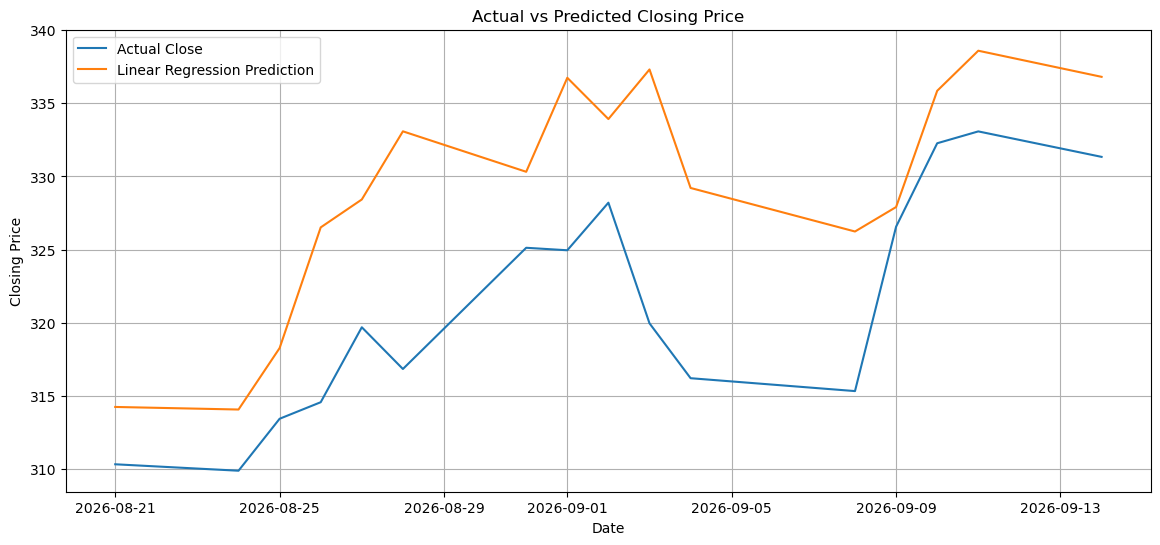

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test,
    label="Actual Close"
)

plt.plot(
    y_test.index,
    y_pred_lr,
    label="Linear Regression Prediction"
)

plt.title("Actual vs Predicted Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)

plt.show()

In [54]:
from sklearn.linear_model import Ridge
# Create Ridge Regression model
ridge_model = Ridge(alpha=1.0)

# Train using only the training period
ridge_model.fit(X_train, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


C:\Users\shini\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.20569e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


In [55]:
# Predict next-day closing prices
y_pred_ridge = ridge_model.predict(X_test)

print("Ridge predictions created.")
print(y_pred_ridge[:10])

Ridge predictions created.
[312.49744846 313.54329951 316.76265463 322.95701953 324.06858871
 326.9149898  325.39976849 330.11150656 330.31085124 331.55785546]


In [56]:
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge)
)

ridge_r2 = r2_score(y_test, y_pred_ridge)

print("===== RIDGE REGRESSION RESULTS =====")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)

===== RIDGE REGRESSION RESULTS =====
MAE : 4.813406001245234
RMSE: 5.965247588606014
R²  : 0.37109334852623954


In [57]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression"
    ],
    "MAE": [
        baseline_mae,
        lr_mae,
        ridge_mae
    ],
    "RMSE": [
        baseline_rmse,
        lr_rmse,
        ridge_rmse
    ],
    "R2": [
        baseline_r2,
        lr_r2,
        ridge_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline,3.633125,4.831931,0.587361
1,Linear Regression,8.103921,9.355189,-0.546801
2,Ridge Regression,4.813406,5.965248,0.371093


In [58]:
from sklearn.ensemble import RandomForestRegressor
# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

# Train only on historical training data
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [59]:
# Predict next-day closing prices
y_pred_rf = rf_model.predict(X_test)

print("Random Forest predictions created.")
print(y_pred_rf[:10])

Random Forest predictions created.
[312.064225  310.001675  311.7381625 313.14375   312.62325   322.5138
 322.35455   325.77905   326.37975   329.6397   ]


In [60]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

rf_r2 = r2_score(y_test, y_pred_rf)

print("===== RANDOM FOREST RESULTS =====")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

===== RANDOM FOREST RESULTS =====
MAE : 4.340882031250036
RMSE: 5.698350423852322
R²  : 0.4261114682175431


In [61]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        lr_mae,
        ridge_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        lr_rmse,
        ridge_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        lr_r2,
        ridge_r2,
        rf_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline,3.633125,4.831931,0.587361
1,Linear Regression,8.103921,9.355189,-0.546801
2,Ridge Regression,4.813406,5.965248,0.371093
3,Random Forest,4.340882,5.698350,0.426111


In [62]:
from sklearn.ensemble import GradientBoostingRegressor
# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train using historical training data
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [63]:
# Predict next-day closing prices
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting predictions created.")
print(y_pred_gb[:10])

Gradient Boosting predictions created.
[312.44909446 309.89846498 311.97132233 311.874727   311.17521015
 322.71495554 324.18342606 327.50263973 322.72635075 326.04048151]


In [64]:
gb_mae = mean_absolute_error(y_test, y_pred_gb)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_gb)
)

gb_r2 = r2_score(y_test, y_pred_gb)

print("===== GRADIENT BOOSTING RESULTS =====")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

===== GRADIENT BOOSTING RESULTS =====
MAE : 4.803665505782817
RMSE: 6.161704186303389
R²  : 0.3289870069435048


In [65]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Ridge Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        baseline_mae,
        lr_mae,
        ridge_mae,
        rf_mae,
        gb_mae
    ],
    "RMSE": [
        baseline_rmse,
        lr_rmse,
        ridge_rmse,
        rf_rmse,
        gb_rmse
    ],
    "R2": [
        baseline_r2,
        lr_r2,
        ridge_r2,
        rf_r2,
        gb_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline,3.633125,4.831931,0.587361
1,Linear Regression,8.103921,9.355189,-0.546801
2,Ridge Regression,4.813406,5.965248,0.371093
3,Random Forest,4.340882,5.698350,0.426111
4,Gradient Boosting,4.803666,6.161704,0.328987


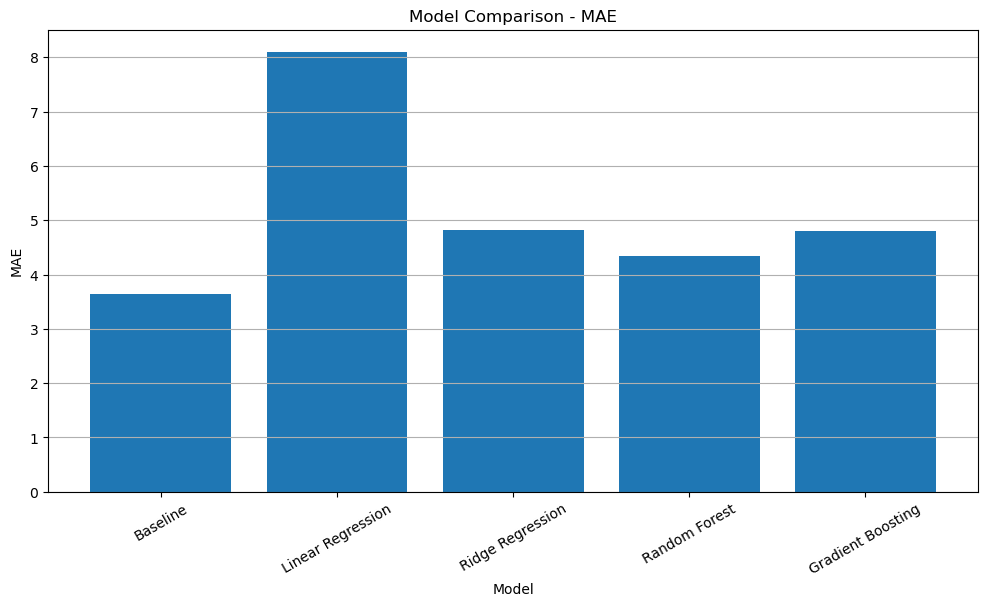

In [66]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison["Model"],
    comparison["MAE"]
)

plt.title("Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()


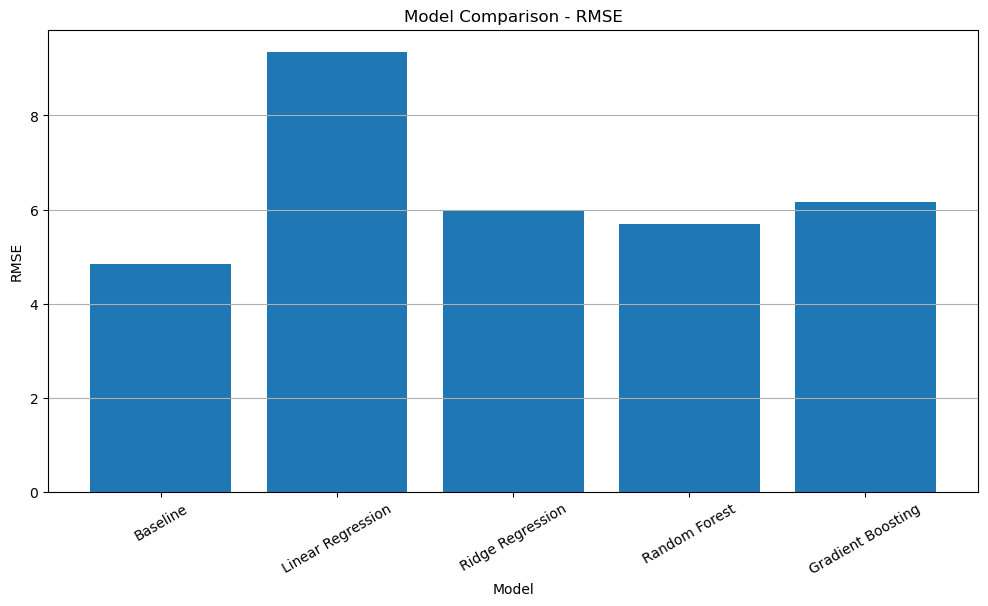

In [67]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison["Model"],
    comparison["RMSE"]
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

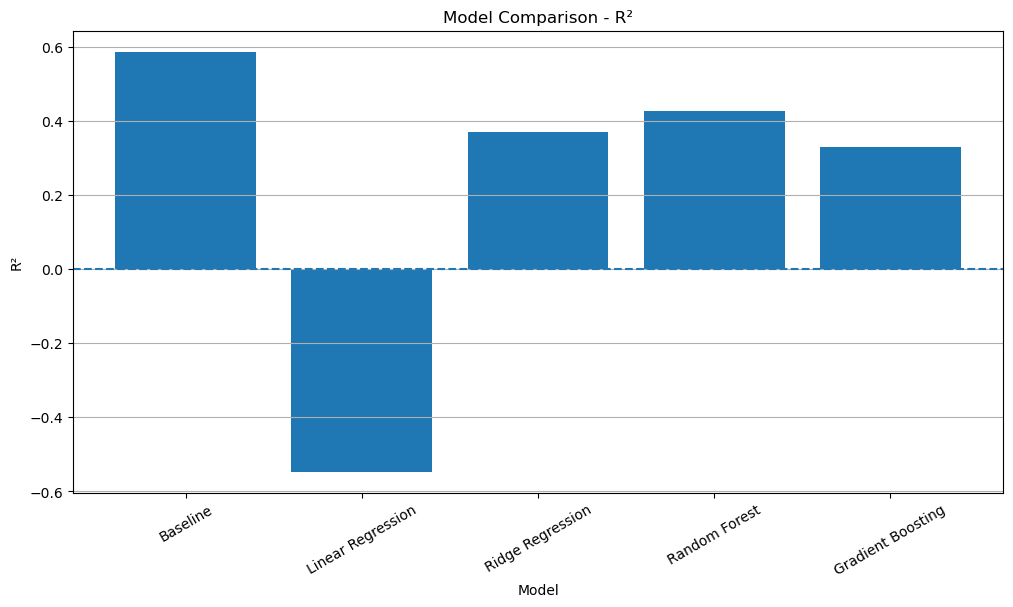

In [68]:
plt.figure(figsize=(12, 6))

plt.bar(
    comparison["Model"],
    comparison["R2"]
)

plt.title("Model Comparison - R²")
plt.xlabel("Model")
plt.ylabel("R²")
plt.xticks(rotation=30)
plt.axhline(0, linestyle="--")
plt.grid(axis="y")

plt.show()

In [69]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [70]:
dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

In [71]:
dt_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [72]:
y_pred_dt = dt_model.predict(X_test)

In [73]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(
    mean_squared_error(y_test, y_pred_dt)
)

r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("--------------------")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R²  :", r2_dt)

Decision Tree Results
--------------------
MAE : 7.452624999999994
RMSE: 10.007934090010773
R²  : -0.7701827866342097


In [74]:
comparison.loc[len(comparison)] = [
    "Decision Tree",
    mae_dt,
    rmse_dt,
    r2_dt
]

comparison

,Model,MAE,RMSE,R2
0,Baseline,3.633125,4.831931,0.587361
1,Linear Regression,8.103921,9.355189,-0.546801
2,Ridge Regression,4.813406,5.965248,0.371093
3,Random Forest,4.340882,5.698350,0.426111
4,Gradient Boosting,4.803666,6.161704,0.328987
5,Decision Tree,7.452625,10.007934,-0.770183


In [75]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
3,Close,0.387325
2,Low,0.267507
1,High,0.065094
0,Open,0.057378
12,Close_Lag_1,0.041867
9,RSI_14,0.041369
5,Daily_Return,0.025162
13,Close_Lag_2,0.022297
11,MACD_Signal,0.011633
6,Volatility_20D,0.011539


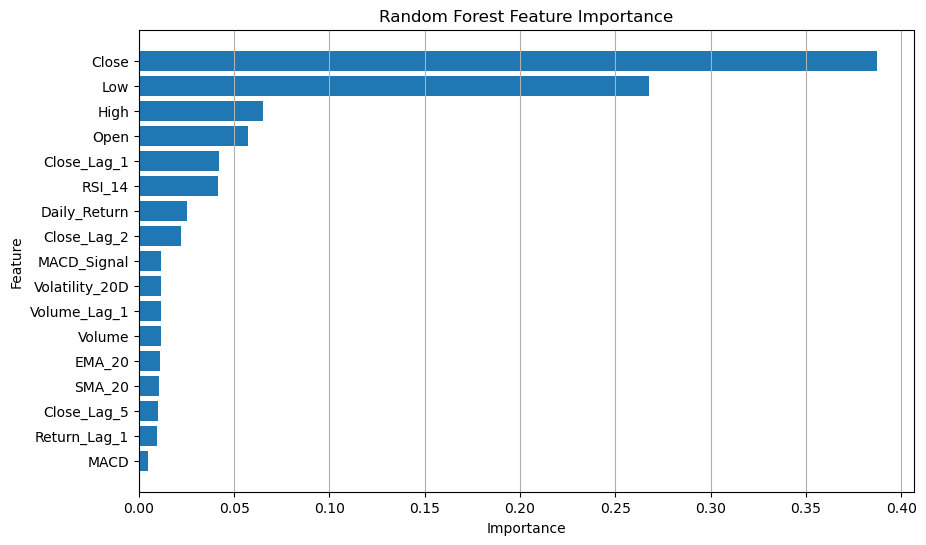

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.grid(axis="x")
plt.show()

In [77]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor

In [78]:
tscv = TimeSeriesSplit(n_splits=5)

print(tscv)

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=None)


In [79]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

In [80]:
rf_tuned = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42
    ),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

In [81]:
rf_tuned.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [5, 10, ...], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [82]:
print("Best Parameters:")
print(rf_tuned.best_params_)

Best Parameters:
{'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}


In [83]:
print("Best CV MAE:")
print(-rf_tuned.best_score_)

Best CV MAE:
10.15669938096239


In [84]:
best_rf = rf_tuned.best_estimator_

print(best_rf)

RandomForestRegressor(max_depth=5, n_estimators=200, random_state=42)


In [85]:
y_pred_tuned_rf = best_rf.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [86]:
mae_tuned = mean_absolute_error(
    y_test,
    y_pred_tuned_rf
)

rmse_tuned = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_tuned_rf
    )
)

r2_tuned = r2_score(
    y_test,
    y_pred_tuned_rf
)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE :", mae_tuned)
print("RMSE:", rmse_tuned)
print("R²  :", r2_tuned)

Tuned Random Forest Results
---------------------------
MAE : 4.345129724744144
RMSE: 5.732801215024461
R²  : 0.4191513209917246


In [87]:
print("Original Random Forest")
print("---------------------")
print("MAE :", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R²  :", r2_score(y_test, y_pred_rf))

print("\nTuned Random Forest")
print("-------------------")
print("MAE :", mae_tuned)
print("RMSE:", rmse_tuned)
print("R²  :", r2_tuned)

Original Random Forest
---------------------
MAE : 4.340882031250036
RMSE: 5.698350423852322
R²  : 0.4261114682175431

Tuned Random Forest
-------------------
MAE : 4.345129724744144
RMSE: 5.732801215024461
R²  : 0.4191513209917246


In [88]:
import joblib
import os

os.makedirs("models", exist_ok=True)

# Original Random Forest save
joblib.dump(
    rf_model,
    "models/random_forest_model.pkl"
)

joblib.dump(
    features,
    "models/feature_list.pkl"
)

print("Model saved successfully!")
print("Feature list saved successfully!")

Model saved successfully!
Feature list saved successfully!


In [89]:
import os

print(os.listdir("models"))

['feature_list.pkl', 'random_forest_model.pkl']


In [90]:
import joblib

model = joblib.load(
    "models/random_forest_model.pkl"
)

feature_list = joblib.load(
    "models/feature_list.pkl"
)

print("Model loaded successfully!")
print("Number of features:", len(feature_list))
print("Features:")
print(feature_list)

Model loaded successfully!
Number of features: 17
Features:
['Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Volatility_20D', 'SMA_20', 'EMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'Return_Lag_1', 'Volume_Lag_1']


In [91]:
import pandas as pd

df_live = pd.read_csv(
    "data/market_data.csv",
    index_col="Date",
    parse_dates=True
)

print(df_live.tail())

               Open    High     Low   Close      Volume
Date                                                   
2026-09-09  315.485  319.15  309.90  315.34  65639962.0
2026-09-10  316.670  326.74  316.51  326.57  70011913.0
2026-09-11  327.450  336.22  326.30  332.27  50716865.0
2026-09-14  334.790  335.50  331.34  333.08  39269147.0
2026-09-15  330.135  331.78  328.35  331.34  31748183.0


In [92]:
# Daily Return
df_live["Daily_Return"] = df_live["Close"].pct_change()

# 20-day volatility
df_live["Volatility_20D"] = (
    df_live["Daily_Return"]
    .rolling(window=20)
    .std()
)

# Moving averages
df_live["SMA_20"] = (
    df_live["Close"]
    .rolling(window=20)
    .mean()
)

df_live["EMA_20"] = (
    df_live["Close"]
    .ewm(
        span=20,
        adjust=False
    )
    .mean()
)

# RSI
delta = df_live["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

df_live["RSI_14"] = (
    100 - (100 / (1 + rs))
)

# MACD
ema_12 = df_live["Close"].ewm(
    span=12,
    adjust=False
).mean()

ema_26 = df_live["Close"].ewm(
    span=26,
    adjust=False
).mean()

df_live["MACD"] = ema_12 - ema_26

df_live["MACD_Signal"] = (
    df_live["MACD"]
    .ewm(
        span=9,
        adjust=False
    )
    .mean()
)

# Lag features
df_live["Close_Lag_1"] = df_live["Close"].shift(1)
df_live["Close_Lag_2"] = df_live["Close"].shift(2)
df_live["Close_Lag_5"] = df_live["Close"].shift(5)

df_live["Return_Lag_1"] = (
    df_live["Daily_Return"].shift(1)
)

df_live["Volume_Lag_1"] = (
    df_live["Volume"].shift(1)
)

In [93]:
latest_data = df_live[feature_list].dropna().tail(1)

print("Latest feature row:")
print(latest_data)

Latest feature row:
               Open    High     Low   Close      Volume  Daily_Return  \
Date                                                                    
2026-09-15  330.135  331.78  328.35  331.34  31748183.0     -0.005224   

            Volatility_20D   SMA_20      EMA_20     RSI_14     MACD  \
Date                                                                  
2026-09-15         0.01514  319.271  321.416794  68.906526  4.29894   

            MACD_Signal  Close_Lag_1  Close_Lag_2  Close_Lag_5  Return_Lag_1  \
Date                                                                           
2026-09-15      2.69971       333.08       332.27       316.22      0.002438   

            Volume_Lag_1  
Date                      
2026-09-15    39269147.0  


In [94]:
prediction = model.predict(latest_data)

print("Predicted Next-Day Close:", prediction[0])

Predicted Next-Day Close: 327.4476000000003
